# 05 · Branching Baselines

## Colab setup

In [1]:
import os
import sys
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/UNIBO/Deep Learning/DL_3C")

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR.mkdir(parents=True, exist_ok=True)
    os.chdir(PROJECT_DIR)
    sys.path.insert(0, str(PROJECT_DIR))
else:
    PROJECT_DIR = Path.cwd()

IMAGES_DIR = PROJECT_DIR / "images"
MODELS_DIR = PROJECT_DIR / "models"
IMAGES_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

print("Working folder:", Path.cwd())
print("Files:", os.listdir())

Mounted at /content/drive
Working folder: /content/drive/MyDrive/UNIBO/Deep Learning/DL_3C
Files: ['06_graph_q_network.ipynb', '07_dqn_training.ipynb', '08_lbd_q_sat_evaluation.ipynb', 'images', 'models', 'train.pkl', 'val.pkl', 'test.pkl', 'test_large.pkl', '01_data_generation.ipynb', '__pycache__', 'neurosat.py', 'history.pkl', '02_model_and_training.ipynb', 'results.pkl', '03_evaluation.ipynb', 'cdcl.py', 'cdcl_check.pkl', '04_cdcl_solver_environment.ipynb', '05_branching_baselines.ipynb']


## Imports

In [2]:
import pickle
import random
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from cdcl import solve, vsids_literal, random_literal

sns.set_theme(style="whitegrid", context="notebook")

## Settings

In [3]:
SEED = 42
RL_TRAIN_SIZE = 2000
RL_TRAIN_MAX_VARS = 20
RL_VAL_SIZE = 100
EVAL_TEST_SIZE = 400
EVAL_LARGE_SIZE = 100
EVAL_LARGE_VARS = [40, 60]
MAX_DECISIONS = 5000

random.seed(SEED)

## Load data

In [4]:
with open("train.pkl", "rb") as f:
    train_data = pickle.load(f)

with open("val.pkl", "rb") as f:
    val_data = pickle.load(f)

with open("test.pkl", "rb") as f:
    test_data = pickle.load(f)

with open("test_large.pkl", "rb") as f:
    large_test_data = pickle.load(f)

print("Train:", len(train_data))
print("Val:  ", len(val_data))
print("Test: ", len(test_data))

Train: 20000
Val:   2000
Test:  2000


## Training formulas for reinforcement learning

In [5]:
small_train = [p for p in train_data if p["n_vars"] <= RL_TRAIN_MAX_VARS]
rl_train = random.sample(small_train, RL_TRAIN_SIZE)

print("Small formulas available:", len(small_train))
print("Training formulas:       ", len(rl_train))
print("SAT share:               ", round(sum(p["label"] for p in rl_train) / len(rl_train), 2))

Small formulas available: 6972
Training formulas:        2000
SAT share:                0.51


## Validation formulas

In [6]:
small_val = [p for p in val_data if p["n_vars"] <= RL_TRAIN_MAX_VARS]
rl_val = random.sample(small_val, RL_VAL_SIZE)

print("Validation formulas:", len(rl_val))

Validation formulas: 100


## Evaluation formulas

In [7]:
eval_sets = {"10–40": random.sample(test_data, EVAL_TEST_SIZE)}
for n in EVAL_LARGE_VARS:
    eval_sets[str(n)] = large_test_data[n][:EVAL_LARGE_SIZE]

for name, data in eval_sets.items():
    print(f"{name:6s}: {len(data)} formulas")

10–40 : 400 formulas
40    : 100 formulas
60    : 100 formulas


## Save datasets

In [8]:
with open("rl_data.pkl", "wb") as f:
    pickle.dump({"train": rl_train, "val": rl_val, "eval": eval_sets}, f)

print("Saved rl_data.pkl")

Saved rl_data.pkl


## DLIS heuristic

In [9]:
def dlis_literal(solver):
    counts = {}
    for clause in solver.clauses[:solver.n_original]:
        if any(solver.value(lit) is True for lit in clause):
            continue
        for lit in clause:
            if solver.value(lit) is None:
                counts[lit] = counts.get(lit, 0) + 1
    if not counts:
        return -solver.unassigned()[0]
    return max(counts, key=counts.get)


HEURISTICS = {
    "VSIDS": vsids_literal,
    "DLIS": dlis_literal,
    "Random": random_literal,
}

## Run function

In [10]:
def run(problem, choose):
    start = time.perf_counter()
    solver = solve(problem["n_vars"], problem["clauses"], choose, MAX_DECISIONS)
    elapsed = time.perf_counter() - start

    return {
        "n_vars": problem["n_vars"],
        "label": problem["label"],
        "finished": solver.result is not None,
        "correct": solver.result == bool(problem["label"]),
        "decisions": solver.decisions,
        "conflicts": solver.conflicts,
        "learned": len(solver.lbds),
        "mean_lbd": sum(solver.lbds) / len(solver.lbds) if solver.lbds else 0,
        "lbds": solver.lbds,
        "ms": elapsed * 1000,
    }

## Run all heuristics

In [11]:
rows = []

for set_name, data in eval_sets.items():
    for heuristic, choose in HEURISTICS.items():
        random.seed(SEED)
        for problem in data:
            row = run(problem, choose)
            row["set"] = set_name
            row["heuristic"] = heuristic
            rows.append(row)
        print(f"Done {set_name} with {heuristic}")

results = pd.DataFrame(rows)

Done 10–40 with VSIDS
Done 10–40 with DLIS
Done 10–40 with Random
Done 40 with VSIDS
Done 40 with DLIS
Done 40 with Random
Done 60 with VSIDS
Done 60 with DLIS
Done 60 with Random


## Correctness check

In [12]:
finished = results[results["finished"]]

print("Runs:                 ", len(results))
print("Unfinished runs:      ", (~results["finished"]).sum())
print("Wrong finished answers:", (~finished["correct"]).sum())

Runs:                  1800
Unfinished runs:       0
Wrong finished answers: 0


## Mean results by heuristic and size

In [13]:
summary = results.groupby(["set", "heuristic"])[["decisions", "conflicts", "mean_lbd", "ms"]].mean().round(2)
print(summary)

                 decisions  conflicts  mean_lbd    ms
set   heuristic                                      
10–40 DLIS            5.16       1.91      1.03  1.59
      Random          5.32       2.70      1.20  1.22
      VSIDS           5.42       2.53      1.19  1.22
40    DLIS            8.01       2.41      1.12  3.32
      Random          8.52       3.54      1.39  2.65
      VSIDS           8.06       3.24      1.38  2.67
60    DLIS           11.66       3.09      1.40  7.05
      Random         12.21       4.55      1.57  5.73
      VSIDS          11.55       4.13      1.71  5.42


## Median decisions

In [14]:
median_decisions = results.pivot_table(index="set", columns="heuristic", values="decisions", aggfunc="median")
print(median_decisions)

heuristic  DLIS  Random  VSIDS
set                           
10–40       4.0     4.0    4.0
40          6.5     8.0    6.0
60         10.5    11.0   11.5


## SAT and UNSAT separately

In [15]:
by_label = results.groupby(["set", "label", "heuristic"])[["decisions", "conflicts", "mean_lbd"]].mean().round(2)
print(by_label)

                       decisions  conflicts  mean_lbd
set   label heuristic                                
10–40 0     DLIS            2.90       3.04      1.28
            Random          3.72       3.71      1.27
            VSIDS           3.62       3.48      1.25
      1     DLIS            7.47       0.76      0.76
            Random          6.94       1.66      1.13
            VSIDS           7.25       1.57      1.13
40    0     DLIS            3.94       3.50      1.32
            Random          6.52       4.98      1.40
            VSIDS           5.22       4.30      1.40
      1     DLIS           12.08       1.32      0.92
            Random         10.52       2.10      1.37
            VSIDS          10.90       2.18      1.35
60    0     DLIS            5.76       4.54      1.48
            Random          7.08       5.16      1.48
            VSIDS           7.38       5.30      1.53
      1     DLIS           17.56       1.64      1.32
            Random         1

## Decisions plot

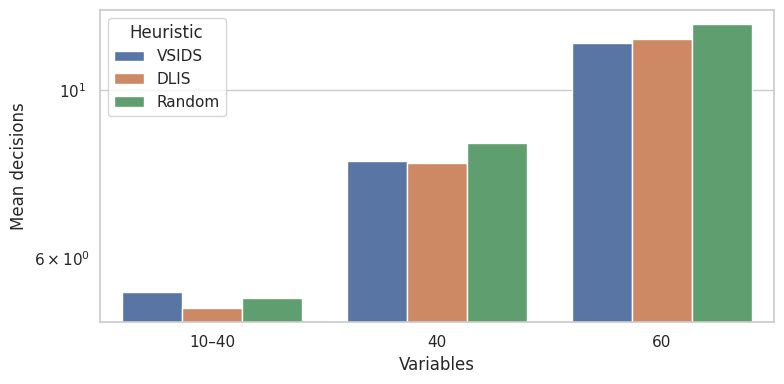

In [16]:
mean_decisions = results.pivot_table(index="set", columns="heuristic", values="decisions", aggfunc="mean")
mean_decisions = mean_decisions.loc[list(eval_sets.keys()), list(HEURISTICS.keys())]

plt.figure(figsize=(8, 4))
ax = sns.barplot(data=results, x="set", y="decisions", hue="heuristic", order=list(eval_sets.keys()), hue_order=list(HEURISTICS.keys()), errorbar=None)
ax.set_yscale("log")
ax.get_legend().set_title("Heuristic")
plt.xlabel("Variables")
plt.ylabel("Mean decisions")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "baseline_decisions.png", dpi=150)
plt.show()

## Conflicts plot

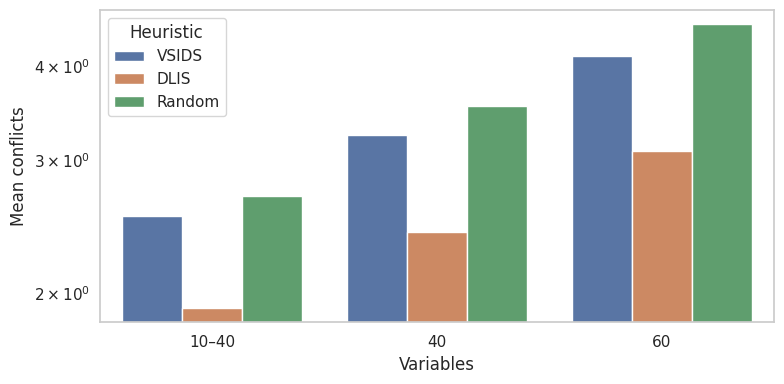

In [17]:
mean_conflicts = results.pivot_table(index="set", columns="heuristic", values="conflicts", aggfunc="mean")
mean_conflicts = mean_conflicts.loc[list(eval_sets.keys()), list(HEURISTICS.keys())]

plt.figure(figsize=(8, 4))
ax = sns.barplot(data=results, x="set", y="conflicts", hue="heuristic", order=list(eval_sets.keys()), hue_order=list(HEURISTICS.keys()), errorbar=None)
ax.set_yscale("log")
ax.get_legend().set_title("Heuristic")
plt.xlabel("Variables")
plt.ylabel("Mean conflicts")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "baseline_conflicts.png", dpi=150)
plt.show()

## LBD distribution by heuristic

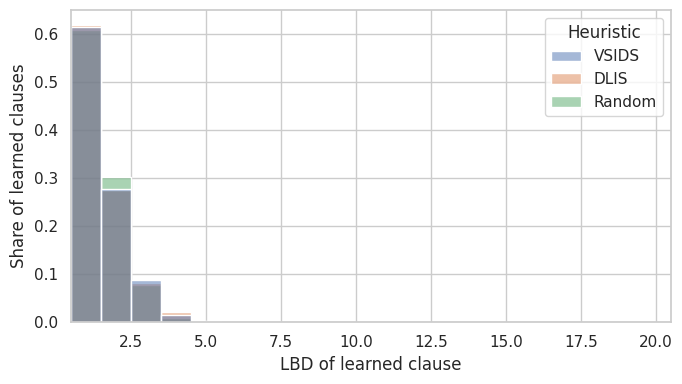

In [18]:
subset = results[results["set"] == "10–40"]
lbd_df = subset[["heuristic", "lbds"]].explode("lbds").dropna().reset_index(drop=True)
lbd_df["lbds"] = lbd_df["lbds"].astype(int)

plt.figure(figsize=(7, 4))
ax = sns.histplot(data=lbd_df, x="lbds", hue="heuristic", hue_order=list(HEURISTICS.keys()), stat="density", common_norm=False, discrete=True, alpha=0.5)
ax.get_legend().set_title("Heuristic")
plt.xlim(0.5, 20.5)
plt.xlabel("LBD of learned clause")
plt.ylabel("Share of learned clauses")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "baseline_lbd_distribution.png", dpi=150)
plt.show()

## LBD and decisions

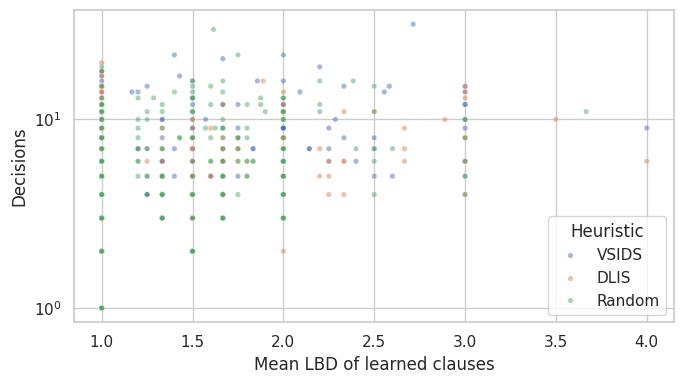

VSIDS  correlation between mean LBD and decisions: 0.48
DLIS   correlation between mean LBD and decisions: 0.46
Random correlation between mean LBD and decisions: 0.50


In [19]:
subset = results[(results["set"] == "10–40") & (results["conflicts"] > 0)]

plt.figure(figsize=(7, 4))
ax = sns.scatterplot(data=subset, x="mean_lbd", y="decisions", hue="heuristic", hue_order=list(HEURISTICS.keys()), s=15, alpha=0.5)
ax.set_yscale("log")
ax.get_legend().set_title("Heuristic")
plt.xlabel("Mean LBD of learned clauses")
plt.ylabel("Decisions")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "baseline_lbd_vs_decisions.png", dpi=150)
plt.show()

for heuristic in HEURISTICS:
    h = subset[subset["heuristic"] == heuristic]
    print(f"{heuristic:6s} correlation between mean LBD and decisions: {h['mean_lbd'].corr(h['decisions'], method='spearman'):.2f}")

## Reference on validation formulas

In [20]:
val_reference = {}

for heuristic, choose in HEURISTICS.items():
    random.seed(SEED)
    rows = [run(p, choose) for p in rl_val]
    val_reference[heuristic] = sum(r["decisions"] for r in rows) / len(rows)
    print(f"{heuristic:6s} mean decisions on validation formulas: {val_reference[heuristic]:.1f}")

VSIDS  mean decisions on validation formulas: 3.2
DLIS   mean decisions on validation formulas: 3.3
Random mean decisions on validation formulas: 3.5


## Save results

In [21]:
with open("baselines.pkl", "wb") as f:
    pickle.dump({"results": results, "val_reference": val_reference}, f)

print("Saved baselines.pkl and the baseline plots")

Saved baselines.pkl and the baseline plots
